In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.astype(int)

print("Dataset Shape:", df.shape)

Dataset Shape: (302, 14)


In [3]:
def split_data(X, y, test_size=0.2, seed=42):

    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []

    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)

        split = int(len(idx) * (1 - test_size))
        train_idx.extend(idx[:split])
        test_idx.extend(idx[split:])

    return (X[train_idx], X[test_idx],
            y[train_idx], y[test_idx])


X_train, X_test, y_train, y_test = split_data(X, y)

In [4]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [5]:
def predict_knn(X_train, y_train, X_test, k):

    predictions = []

    for query in X_test:

        distances = np.sqrt(
            np.sum((X_train - query) ** 2, axis=1)
        )

        indices = np.argpartition(distances, k - 1)[:k]

        labels = y_train[indices]
        classes, counts = np.unique(labels, return_counts=True)

        tied = classes[counts == counts.max()]

        if len(tied) == 1:
            prediction = tied[0]
        else:
            nearest = indices[np.argmin(distances[indices])]
            prediction = y_train[nearest]

        predictions.append(prediction)

    return np.array(predictions)

In [6]:
k_values = range(1, 22, 2)
error_rates = []
accuracies = []

for k in k_values:

    predictions = predict_knn(
        X_train, y_train, X_test, k
    )

    errors = np.sum(predictions != y_test)
    error_rate = errors / len(y_test)

    accuracy = 1 - error_rate

    error_rates.append(error_rate)
    accuracies.append(accuracy * 100)

    print(
        f"K = {k} | Error Rate = {error_rate:.4f} "
        f"| Accuracy = {accuracy * 100:.2f}%"
    )

K = 1 | Error Rate = 0.2459 | Accuracy = 75.41%
K = 3 | Error Rate = 0.1803 | Accuracy = 81.97%
K = 5 | Error Rate = 0.1148 | Accuracy = 88.52%
K = 7 | Error Rate = 0.1639 | Accuracy = 83.61%
K = 9 | Error Rate = 0.1475 | Accuracy = 85.25%
K = 11 | Error Rate = 0.1475 | Accuracy = 85.25%
K = 13 | Error Rate = 0.1639 | Accuracy = 83.61%
K = 15 | Error Rate = 0.1148 | Accuracy = 88.52%
K = 17 | Error Rate = 0.1639 | Accuracy = 83.61%
K = 19 | Error Rate = 0.1475 | Accuracy = 85.25%
K = 21 | Error Rate = 0.1639 | Accuracy = 83.61%


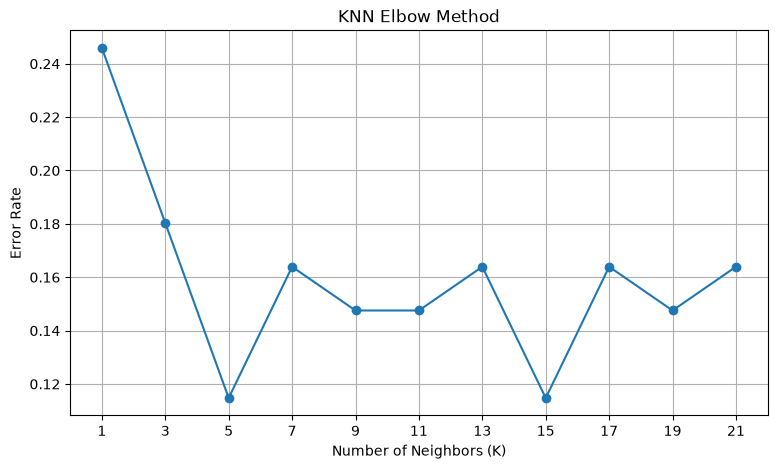

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    error_rates,
    marker="o"
)

plt.title("KNN Elbow Method")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Error Rate")
plt.xticks(list(k_values))
plt.grid()
plt.show()

In [8]:
best_index = np.argmin(error_rates)

best_k = list(k_values)[best_index]
best_error = error_rates[best_index]
best_accuracy = accuracies[best_index]

print("Selected K:", best_k)
print("Minimum Error Rate:", round(best_error, 4))
print("Best Accuracy:", round(best_accuracy, 2), "%")

Selected K: 5
Minimum Error Rate: 0.1148
Best Accuracy: 88.52 %


## Conclusion

In this task, the optimal K value for the K-Nearest Neighbors
classifier was investigated using the Elbow Method.

Different K values were tested, and their classification error
rates were calculated manually.

An error-rate curve was plotted to visualize how the choice
of K affects model performance.

The K value with the lowest observed error rate was selected
as the best-performing value among the tested candidates.